# 06 Fine-tuning de `unet_effb0_tout` avec occlusion

Apprendre au modèle à suivre une racine cachée par de la terre : à l'entraînement, on colle des morceaux de sol sur les racines, le masque restant entier (notebook E2, section 5). Pour gagner du temps, on affine le modèle du notebook 05 au lieu de repartir de zéro.

**L'essentiel** : aucun gain. Aucune époque ne dépasse le modèle de départ sur le val (arrêt à l'époque 10), et les fausses détections augmentent pendant l'affinage (jusqu'à 64 % des images vides touchées). L'occlusion n'est pas retenue.

Réglages :
- occlusion sur 50 % des carrés avec racine : 1 ou 2 taches de sol de la même image, de taille proportionnelle au diamètre de la racine (environ 8 % de la longueur de racine cachée en tout) ;
- taux d'apprentissage divisés par 10 (1e-4 et 1e-5), 30 époques au plus, patience de 10, arrêt précoce sur le val corrigé ;
- le modèle de départ est évalué avant l'affinage (époque 0) : il reste le meilleur si aucune époque ne le dépasse.

Limite : un seul essai, à une seule dose, en affinage. Pratique : environ 80 s par époque ; le train (environ 4 Go) n'est chargé que si l'entraînement est à faire.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from prmi import viz
from prmi.dataset import VAL_LARGE, RootCrops, draw_extra, load_extra, load_lot, population, to_display
from prmi.diagnostic import overlay_mask
from prmi.train import compare_runs, load_run, predict, run_exists, score_items, score_run, summarize, train, train_eval_items

viz.apply_style()
pd.set_option('display.width', 180)
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 90

SCALE = 2
CROPS_PER_EPOCH = 596
EPOCHS = 30
PATIENCE = 10
LR, ENCODER_LR = 1e-4, 1e-5                # notebook 05 : 1e-3 et 1e-4
OCCLUSION = 0.5                            # probabilité d'occlusion d'un carré avec racine
NAME = 'unet_effb0_tout_occ'
BASE = 'unet_effb0_tout'                   # notebook 05, point de départ
OTHERS = ['unet_effb0_s2_aug', 'unet_effb0_1000']   # notebooks 03 et 04
VAL_FILE = 'val_images.csv'                # scores sur le val corrigé
N_VAL_LARGE = 1000

## 1. Données

In [2]:
clean = load_lot('train', SCALE)                                       # 149 images, masques corrigés
val_items = load_lot('val', SCALE)                                     # masques corrigés
val_large = draw_extra(N_VAL_LARGE, path=VAL_LARGE, split='val')       # grand val (relu)
print(len(clean), 'images corrigées,', len(val_items), 'images de val,', len(val_large), 'images de grand val')

149 images corrigées, 74 images de val, 1000 images de grand val


Carrés avec occlusion forcée (probabilité 1, pour voir l'effet ; 0,5 à l'entraînement), pris dans les 149 images corrigées. Masque en aplat bleu : il passe sous la terre collée.

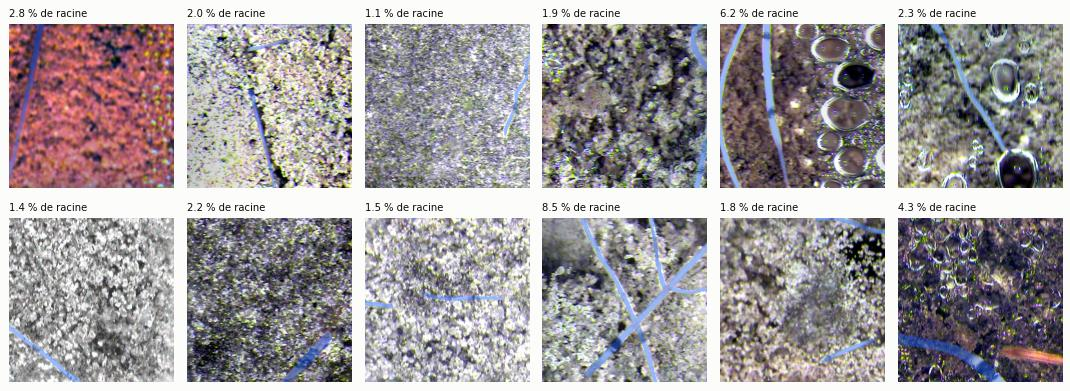

In [3]:
crops = RootCrops(clean, seed=1, augment=True, occlusion=1.0)
pairs = [p for p in (crops[i] for i in range(0, 300, 5)) if p[1].mean() > 0.01][:12]
images = [overlay_mask(to_display(x), y[0].numpy() > 0) for x, y in pairs]
viz.image_grid(images, [f'{y.mean() * 100:.1f} % de racine' for _, y in pairs], ncols=6);

## 2. Entraînement

Si l'entraînement existe déjà sous ce nom, il n'est pas relancé (et le train n'est pas chargé). En cas d'arrêt manuel, passer à la cellule suivante.

In [4]:
if run_exists(NAME):
    print('Entraînement déjà présent, relecture de', NAME)
else:
    rows = population('train')
    train_items = clean + load_extra(rows, SCALE, compact=True)        # masques d'origine comblés, environ 3 min
    train(train_items, val_items, NAME, epochs=EPOCHS, patience=PATIENCE, lr=LR, encoder_lr=ENCODER_LR, augment=True,
          crops_per_epoch=CROPS_PER_EPOCH, train_eval=train_eval_items(clean), occlusion=OCCLUSION,
          init=BASE)                       # Dice train : mêmes 44 images corrigées
    del train_items

cpu, 926,521 paramètres utilisés, 11485 images train, 74 images val, 74 batchs par époque
  0  départ (unet_effb0_tout) : Dice val 0.741  global 0.778
  1/30  perte train 0.195  val 0.103  Dice train 0.737  val 0.743  global 0.777  clDice 0.843  racines 90%  fantômes 37  longueur 0.13  images vides touchées 0.46  lr 1.0e-05 / 1.0e-04  87 s
  2/30  perte train 0.221  val 0.104  Dice train 0.741  val 0.734  global 0.776  clDice 0.832  racines 87%  fantômes 36  longueur 0.13  images vides touchées 0.50  lr 1.0e-05 / 1.0e-04  83 s
  3/30  perte train 0.238  val 0.105  Dice train 0.740  val 0.733  global 0.775  clDice 0.830  racines 87%  fantômes 47  longueur 0.12  images vides touchées 0.64  lr 9.9e-06 / 9.9e-05  84 s
  4/30  perte train 0.210  val 0.103  Dice train 0.741  val 0.735  global 0.775  clDice 0.832  racines 87%  fantômes 50  longueur 0.12  images vides touchées 0.64  lr 9.8e-06 / 9.8e-05  85 s
  5/30  perte train 0.232  val 0.105  Dice train 0.740  val 0.731  global 0.775  clDi

,epoch,lr,lr_encoder,train_loss,train_dice,dice,global_dice,roots_found,ghosts,length_err,fp_empty,cldice,global_cldice,val_loss,seconds
0,0,0.0001,0.00001,NaN,0.74194,0.741471,0.777581,0.877193,29,0.139656,0.428571,0.841781,0.875679,0.103294,11.212014


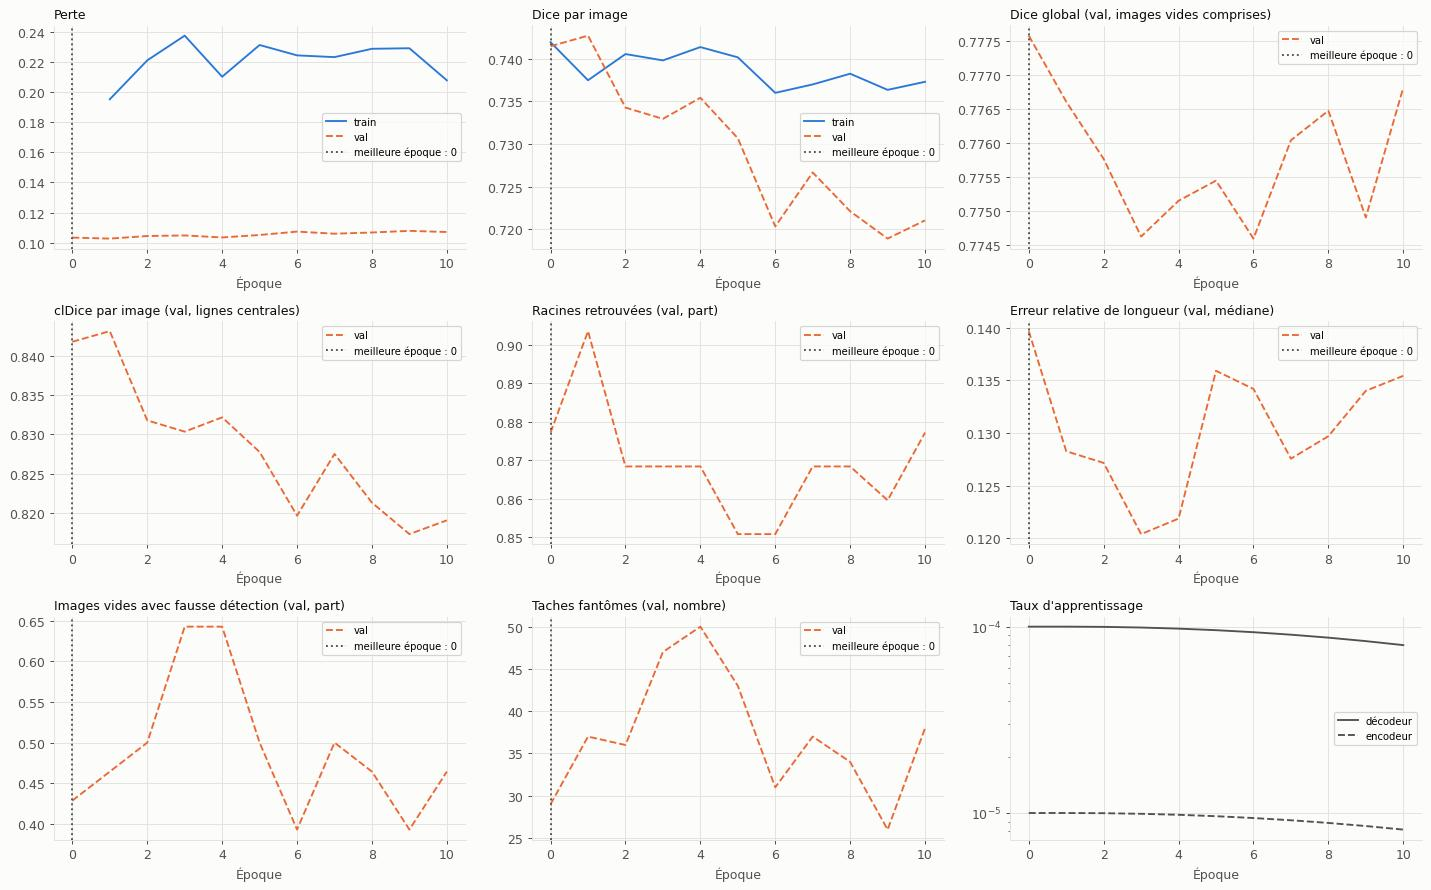

In [5]:
model, history, best_epoch, _ = load_run(NAME)
device = next(model.parameters()).device
viz.plot_history(history, best_epoch);
history.loc[history['epoch'] == best_epoch]

## 3. Val corrigé : comparaison avec le modèle de départ

Image par image sur les images avec racine (écart = affiné avec occlusion moins départ). Pour l'erreur de longueur, un écart négatif est un progrès.

In [6]:
tables = {n: score_items(n, val_items, VAL_FILE) for n in OTHERS + [BASE, NAME]}     # calculé une fois, puis relu
per_image = tables[NAME]
display(pd.DataFrame({n: summarize(t) for n, t in tables.items()}).T.round(3))

rows_cmp = {metric: compare_runs(BASE, NAME, metric, VAL_FILE)[1] for metric in ['dice', 'cldice', 'length_err']}
pd.DataFrame(rows_cmp).T.round(4)

,dice,global_dice,roots_found,ghosts,length_err,fp_empty,cldice,global_cldice
unet_effb0_s2_aug,0.685,0.765,0.798,32.0,0.151,0.393,0.777,0.852
unet_effb0_1000,0.698,0.765,0.798,29.0,0.157,0.357,0.796,0.860
unet_effb0_tout,0.741,0.778,0.877,29.0,0.140,0.429,0.842,0.876
unet_effb0_tout_occ,0.741,0.778,0.877,29.0,0.140,0.429,0.842,0.876


/home/francois/anaconda3/envs/dl2/lib/python3.13/site-packages/scipy/stats/_wilcoxon.py:181: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/home/francois/anaconda3/envs/dl2/lib/python3.13/site-packages/scipy/stats/_wilcoxon.py:181: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/home/francois/anaconda3/envs/dl2/lib/python3.13/site-packages/scipy/stats/_wilcoxon.py:181: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


,images,écart moyen,écart médian,b meilleur,b moins bon,p (Wilcoxon)
dice,46.0,0.0,0.0,0.0,0.0,NaN
cldice,46.0,0.0,0.0,0.0,0.0,NaN
length_err,46.0,0.0,0.0,0.0,0.0,NaN


## 4. Grand val (masques d'origine comblés)

Évaluation une fois sur les 1 000 images (environ 2 min, lues sur la clé), puis relue.

In [7]:
runs = OTHERS + [BASE, NAME]
large = {n: score_run(n, val_large) for n in runs}
display(pd.DataFrame({n: summarize(t) for n, t in large.items()}).T.round(3))

rows_cmp = {metric: compare_runs(BASE, NAME, metric, 'val_large_comble_images.csv')[1] for metric in ['dice', 'cldice', 'length_err']}
pd.DataFrame(rows_cmp).T.round(4)

,dice,global_dice,roots_found,ghosts,length_err,fp_empty,cldice,global_cldice
unet_effb0_s2_aug,0.645,0.701,0.641,762.0,0.221,0.451,0.740,0.780
unet_effb0_1000,0.668,0.716,0.667,690.0,0.221,0.391,0.768,0.800
unet_effb0_tout,0.684,0.721,0.698,801.0,0.198,0.470,0.781,0.801
unet_effb0_tout_occ,0.684,0.721,0.698,801.0,0.198,0.470,0.781,0.801


/home/francois/anaconda3/envs/dl2/lib/python3.13/site-packages/scipy/stats/_wilcoxon.py:181: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/home/francois/anaconda3/envs/dl2/lib/python3.13/site-packages/scipy/stats/_wilcoxon.py:181: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/home/francois/anaconda3/envs/dl2/lib/python3.13/site-packages/scipy/stats/_wilcoxon.py:181: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


,images,écart moyen,écart médian,b meilleur,b moins bon,p (Wilcoxon)
dice,568.0,0.0,0.0,0.0,0.0,NaN
cldice,568.0,0.0,0.0,0.0,0.0,NaN
length_err,568.0,0.0,0.0,0.0,0.0,NaN


## 5. Images

Val corrigé au curseur : référence à gauche, prédiction à droite, du plus bas Dice au plus haut, images sans racine à la fin.

In [8]:
preds = {it['name']: predict(model, it, device) for it in val_items}
viz.browse_predictions(val_items, preds, per_image)

interactive(children=(IntSlider(value=0, continuous_update=False, description='Image', layout=Layout(width='80…

## 6. À retenir

- **Meilleure époque : 0**, c'est-à-dire le modèle de départ : les tableaux ci-dessus sont identiques pour les deux modèles.
- **Pendant l'affinage** : Dice global stable (0,775 à 0,777), Dice par image en légère baisse, fantômes et images vides touchées en hausse. Le modèle apprend à prolonger les racines là où il n'y en a pas.
- **Occlusion abandonnée** ; `unet_effb0_tout` reste le modèle retenu.